In [19]:
# imports

import math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt


In [20]:
# variables
IMG_SIZE = 32
EMBED_DIM = 64
ATTENTION_HEADS = 4
BATCH_SIZE = 12
EPOCHS = 40
LR = 3e-4
TEMPERATURE = 0.07
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [21]:
# synthetic dataset properties

colors = ['red', 'green', 'blue', 'yellow', 'purple', 'orange', 'pink', 'brown', 'gray']

shapes = ['square', 'circle', 'triangle']

positions = ['left', 'center', 'right', 'top', 'bottom', 'top-left', 'top-right', 'bottom-left', 'bottom-right']


In [22]:
# Drawing image shape

def draw_sample(color, shape, position, img_size = IMG_SIZE):
  img = Image.new('RGB',(img_size, img_size),'white')
  draw = ImageDraw.Draw(img)

  margin = 6
  w = h = img_size - 2*margin

    # Calculate x coordinates
  if 'left' in position:
      x0 = margin
      x1 = margin + w // 2
  elif 'top-left' in position:
      x0 = margin
      x1 = margin + w // 2
  elif 'bottom-left' in position:
      x0 = margin
      x1 = margin + w // 2
  elif 'right' in position:
      x0 = margin + w // 2
      x1 = img_size - margin
  elif 'top-right' in position:
      x0 = margin + w // 2
      x1 = img_size - margin
  elif 'bottom-right' in position:
      x0 = margin + w // 2
      x1 = img_size - margin
  else:  # center or vertical positions
      x0 = margin + w // 4
      x1 = margin + 3 * w // 4


  # Calculate y coordinates
  if 'top' in position:
      y0 = margin
      y1 = margin + h // 2
  elif 'top-left' in position:
      y0 = margin
      y1 = margin + h // 2
  elif 'top-right' in position:
      y0 = margin
      y1 = margin + h // 2
  elif 'bottom' in position:
      y0 = margin + h // 2
      y1 = img_size - margin
  elif 'bottom-left' in position:
      y0 = margin + h // 2
      y1 = img_size - margin
  elif 'bottom-right' in position:
      y0 = margin + h // 2
      y1 = img_size - margin
  else:  # center or horizontal positions
      y0 = margin + h // 4
      y1 = margin + 3 * h // 4


  if shape == 'square':
      draw.rectangle([x0, y0, x1, y1], fill=color, outline='black')
  elif shape == 'circle':
      draw.ellipse([x0, y0, x1, y1], fill=color, outline='black')
  else:  # triangle
      draw.polygon([(x0 + (x1 - x0) // 2, y0), (x0, y1), (x1, y1)],
                  fill=color, outline='black')

  return img


In [23]:
# Class for building the dataset

class ShapesDataset:
    def __init__(self):
        self.images = []
        self.captions = []

        for c in colors:
            for s in shapes:
                for p in positions:
                    img = draw_sample(c, s, p)
                    cap = f"{c} {s} {p}"

                    self.images.append(
                        torch.from_numpy(np.asarray(img))
                        .permute(2, 0, 1)
                        .float() / 255.0
                    )

                    self.captions.append(cap)

        self.vocab, self.word2idx = self.build_vocab(self.captions)

    def build_vocab(self, texts):
        words = sorted({w for t in texts for w in t.split()})
        vocab = ['[CLS]'] + words
        w2i = {w: i for i, w in enumerate(vocab)}
        return vocab, w2i

    def encode_text(self, text):
        toks = [self.word2idx['[CLS]']] + [
            self.word2idx[w] for w in text.split()
        ]
        return torch.tensor(toks, dtype=torch.long)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return (
            self.images[i],
            self.encode_text(self.captions[i]),
            self.captions[i]
        )


# Create the full dataset
full_ds = ShapesDataset()
VOCAB_SIZE = len(full_ds.vocab)

In [24]:
# create full dataset

full_ds =ShapesDataset()
VOCAB_SIZE = len(full_ds.vocab)
print(VOCAB_SIZE)
print(full_ds.vocab)

22
['[CLS]', 'blue', 'bottom', 'bottom-left', 'bottom-right', 'brown', 'center', 'circle', 'gray', 'green', 'left', 'orange', 'pink', 'purple', 'red', 'right', 'square', 'top', 'top-left', 'top-right', 'triangle', 'yellow']


In [25]:
# train val data creation

train_size = int(0.8 * len(full_ds))
val_size = len(full_ds) - train_size

train_ds, val_ds = torch.utils.data.random_split(full_ds, [train_size, val_size])

print(len(train_ds))
print(len(val_ds))

194
49


In [26]:
# dataloader

train_loader = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle = True)
val_loader = DataLoader(val_ds, batch_size = BATCH_SIZE, shuffle = True)

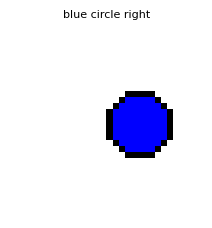

In [27]:
# display sample datapoint
imgs, encoded_caps, raw_caps = next(iter(train_loader))

idx = random.randint(0, len(imgs) - 1)

img = (imgs[idx].permute(1, 2, 0).numpy() * 255).astype(np.uint8)

# Decode the caption
caption_tokens = encoded_caps[idx].tolist()

caption = " ".join(
    [full_ds.vocab[token] for token in caption_tokens
     if token in range(len(full_ds.vocab))]
)

# Remove the [CLS] token if present
caption = caption.replace("[CLS] ", "")

plt.figure(figsize=(2.5, 2.5))
plt.imshow(img)
plt.title(caption, fontsize=8)
plt.axis("off")
plt.show()

In [28]:
# image encoder


class ImageEncoder(nn.Module):
  def __init__(self, e_dim = EMBED_DIM):
    super().__init__()

    self.convs = nn.Sequential(
        nn.Conv2d(3, 32, 3, stride = 2, padding = 1),
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, stride =2, padding = 1),
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, stride = 2, padding = 1),
        nn.ReLU(),
        nn.Conv2d(128, 256, 3, stride = 2, padding = 1),
        nn.ReLU()
    )

    self.projection = nn.Linear(256, e_dim)
    self.layernorm1 = nn.LayerNorm(e_dim)


  def forward(self, x):
    x = self.convs(x)
    x = x.mean(dim = [2,3])
    x = self.projection(x)
    x = F.normalize( self.layernorm1(x), dim = 1)
    return x



In [29]:
class TextEncoder(nn.Module):
  def __init__(self, em_dim = EMBED_DIM, vocab_size = VOCAB_SIZE, num_head = ATTENTION_HEADS, context_window = 4):
    super().__init__()

    self.token_embedding = nn.Embedding(vocab_size, em_dim)
    self.position_embedding = nn.Embedding(context_window, em_dim)
    self.mha = nn.MultiheadAttention(em_dim, num_head)
    self.projection = nn.Linear(em_dim, em_dim)
    self.norm = nn.LayerNorm(em_dim)



  def forward(self, toks):
    N, L = toks.shape
    position_emb_id = torch.arange(L, device = toks.device).unsqueeze(0).expand(N,L)
    position_embedding_vector = self.position_embedding(position_emb_id)

    token_embedding_vectors = self.token_embedding(toks)

    x = token_embedding_vectors + position_embedding_vector

    # MultiheadAttention expects (Sequence_Length, Batch_Size, Embedding_Dim)
    x = x.permute(1, 0, 2)
    x = self.mha(x,x,x)[0]
    # Permute back to (Batch_Size, Sequence_Length, Embedding_Dim)
    x = x.permute(1, 0, 2)

    # Correctly select the CLS token (first token in sequence) instead of slicing with x[:0]
    x = x[:, 0]
    x = self.projection(x)
    x = F.normalize(self.norm(x), dim = -1)

    return x

In [30]:
# clip loss

def clip_loss(img_emb, txt_emb, tem = TEMPERATURE):
  logits = img_emb @ txt_emb.T / tem
  targets = torch.arange(img_emb.size(0), device = img_emb.device)
  loss_i = F.cross_entropy(logits, targets)
  loss_t = F.cross_entropy(logits.T, targets)
  return ((loss_i+ loss_t)/2.0)


In [31]:
# model , data, optimizer

# We can now safely use the global 'device' variable directly
img_encoder = ImageEncoder().to(device)
text_encoder = TextEncoder().to(device)

params = list(img_encoder.parameters()) + list(text_encoder.parameters())
optimizer = torch.optim.Adam(params, lr = LR)

Sample image and caption for embeddings visualization: 'gray triangle top-right'


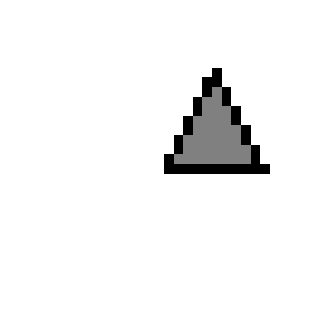

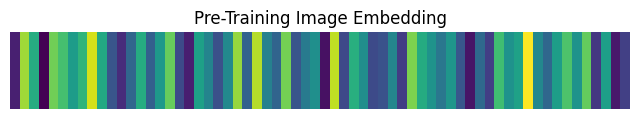

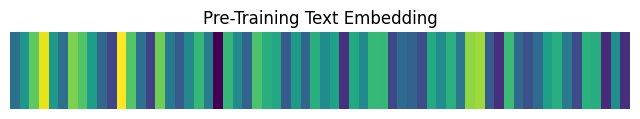

In [32]:
img_encoder.eval()
text_encoder.eval()

with torch.no_grad():
    random_idx = random.randrange(len(full_ds))

    sample_img, sample_toks, sample_cap = full_ds[random_idx]

    # Use the correct target_device variable
    sample_img_gpu = sample_img.unsqueeze(0).to(device)
    sample_toks_gpu = sample_toks.unsqueeze(0).to(device)

    # Use the correct model names: img_encoder and text_encoder
    pre_train_img_emb = img_encoder(sample_img_gpu).cpu().numpy()
    pre_train_txt_emb = text_encoder(sample_toks_gpu).cpu().numpy()

print(f"Sample image and caption for embeddings visualization: '{sample_cap}'")

plt.figure(figsize=(4, 4))
plt.imshow(sample_img.permute(1, 2, 0)) # Plot original CPU tensor
plt.axis('off')
plt.show()

def plot_embedding(embedding, title):
    plt.figure(figsize=(8, 1))
    plt.imshow(embedding.reshape(1, -1), aspect='auto', cmap='viridis')
    plt.title(title)
    plt.axis('off')
    plt.show()

plot_embedding(pre_train_img_emb, "Pre-Training Image Embedding")
plot_embedding(pre_train_txt_emb, "Pre-Training Text Embedding")

In [33]:
# Training loop

for epoch in range(EPOCHS):
    img_encoder.train()
    text_encoder.train()
    epoch_loss = 0.0

    for batch_idx, (imgs, encoded_caps, _) in enumerate(train_loader):
        # Move data to the target device
        imgs = imgs.to(device)
        encoded_caps = encoded_caps.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        img_embeddings = img_encoder(imgs)
        txt_embeddings = text_encoder(encoded_caps)

        # Calculate contrastive loss
        loss = clip_loss(img_embeddings, txt_embeddings, tem=TEMPERATURE)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * imgs.size(0)

    # Calculate average loss over epoch
    epoch_loss /= len(train_loader.dataset)

    # Validation step
    img_encoder.eval()
    text_encoder.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, encoded_caps, _ in val_loader:
            imgs = imgs.to(device)
            encoded_caps = encoded_caps.to(device)

            img_embeddings = img_encoder(imgs)
            txt_embeddings = text_encoder(encoded_caps)

            loss = clip_loss(img_embeddings, txt_embeddings, tem=TEMPERATURE)
            val_loss += loss.item() * imgs.size(0)
        val_loss /= len(val_loader.dataset)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch [1/40] | Train Loss: 2.5217 | Val Loss: 2.4234
Epoch [2/40] | Train Loss: 2.4188 | Val Loss: 2.3488
Epoch [3/40] | Train Loss: 2.1355 | Val Loss: 2.4133
Epoch [4/40] | Train Loss: 1.7033 | Val Loss: 1.4053
Epoch [5/40] | Train Loss: 0.8702 | Val Loss: 0.8395
Epoch [6/40] | Train Loss: 0.5745 | Val Loss: 0.4262
Epoch [7/40] | Train Loss: 0.3206 | Val Loss: 0.2128
Epoch [8/40] | Train Loss: 0.3313 | Val Loss: 0.2933
Epoch [9/40] | Train Loss: 0.2534 | Val Loss: 0.2042
Epoch [10/40] | Train Loss: 0.1714 | Val Loss: 0.1422
Epoch [11/40] | Train Loss: 0.1802 | Val Loss: 0.1472
Epoch [12/40] | Train Loss: 0.1654 | Val Loss: 0.1986
Epoch [13/40] | Train Loss: 0.1820 | Val Loss: 0.1729
Epoch [14/40] | Train Loss: 0.1417 | Val Loss: 0.1225
Epoch [15/40] | Train Loss: 0.1158 | Val Loss: 0.2294
Epoch [16/40] | Train Loss: 0.1132 | Val Loss: 0.0964
Epoch [17/40] | Train Loss: 0.1178 | Val Loss: 0.1433
Epoch [18/40] | Train Loss: 0.1276 | Val Loss: 0.0845
Epoch [19/40] | Train Loss: 0.1811 | 

Sample image and caption for trained embeddings visualization: 'blue triangle top'


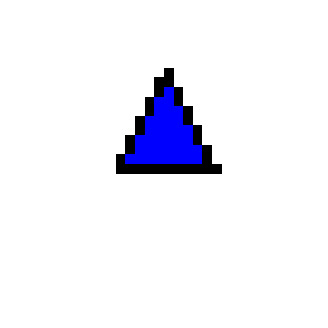

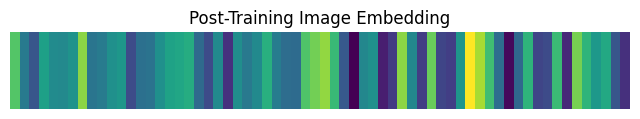

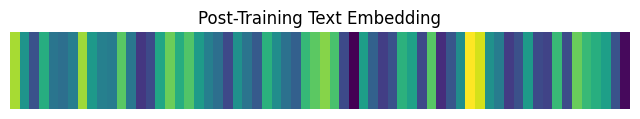

In [34]:
img_encoder.eval()
text_encoder.eval()

with torch.no_grad():
    random_idx = random.randrange(len(full_ds))

    sample_img, sample_toks, sample_cap = full_ds[random_idx]

    # Move inputs to target device
    sample_img_gpu = sample_img.unsqueeze(0).to(device)
    sample_toks_gpu = sample_toks.unsqueeze(0).to(device)

    # Extract post-training embeddings
    post_train_img_emb = img_encoder(sample_img_gpu).cpu().numpy()
    post_train_txt_emb = text_encoder(sample_toks_gpu).cpu().numpy()

print(f"Sample image and caption for trained embeddings visualization: '{sample_cap}'")

plt.figure(figsize=(4, 4))
plt.imshow(sample_img.permute(1, 2, 0))
plt.axis('off')
plt.show()

def plot_embedding(embedding, title):
    plt.figure(figsize=(8, 1))
    plt.imshow(embedding.reshape(1, -1), aspect='auto', cmap='viridis')
    plt.title(title)
    plt.axis('off')
    plt.show()

plot_embedding(post_train_img_emb, "Post-Training Image Embedding")
plot_embedding(post_train_txt_emb, "Post-Training Text Embedding")

In [35]:
# Calculate dot products (cosine similarity since embeddings are normalized)
pre_similarity = (pre_train_img_emb @ pre_train_txt_emb.T).item()
post_similarity = (post_train_img_emb @ post_train_txt_emb.T).item()

print(f"For matching pair: '{sample_cap}'")
print(f"-> Pre-training similarity (dot product):  {pre_similarity:.4f}")
print(f"-> Post-training similarity (dot product): {post_similarity:.4f}")

For matching pair: 'blue triangle top'
-> Pre-training similarity (dot product):  -0.0645
-> Post-training similarity (dot product): 0.8962


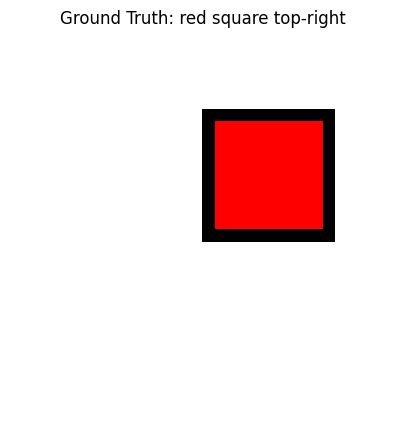

Model Top Predictions:
1. red square top-right - Similarity: 0.9090 ✅
2. red circle top-right - Similarity: 0.8586 ❌
3. orange square top-right - Similarity: 0.7606 ❌


In [37]:
img_encoder.eval()
text_encoder.eval()

# 1. Grab a random test sample from the dataset
random_idx = random.randrange(len(full_ds))
sample_img, _, true_caption = full_ds[random_idx]

# 2. Get the target image embedding
sample_img_gpu = sample_img.unsqueeze(0).to(device)
with torch.no_grad():
    img_emb = img_encoder(sample_img_gpu) # Shape: (1, EMBED_DIM)

# 3. Embed all possible candidate captions to match against
# We will use all captions in our dataset as candidates to see if the model identifies the exact match
candidate_captions = list(set(full_ds.captions))
encoded_candidates = torch.stack([full_ds.encode_text(cap) for cap in candidate_captions]).to(device)

with torch.no_grad():
    txt_embs = text_encoder(encoded_candidates) # Shape: (Num_Candidates, EMBED_DIM)

# 4. Compute cosine similarity between the image and all captions
similarities = (img_emb @ txt_embs.T).squeeze(0).cpu().numpy()

# 5. Get top predictions
top_indices = similarities.argsort()[::-1][:3]

# 6. Visualize the prediction results
plt.figure(figsize=(5, 5))
plt.imshow(sample_img.permute(1, 2, 0))
plt.axis('off')
plt.title(f"Ground Truth: {true_caption}", fontsize=12, pad=10)
plt.show()

print("Model Top Predictions:")
for i, idx in enumerate(top_indices):
    match_symbol = "✅" if candidate_captions[idx] == true_caption else "❌"
    print(f"{i+1}. {candidate_captions[idx]} - Similarity: {similarities[idx]:.4f} {match_symbol}")